# Лабораторна робота №3 — Основи штучного інтелекту
### Варіант 9 · Нелінійна регресія, поліноми та багатошарові перцептрони

**Завдання LMS:** ознайомитися з прикладами **№4, №5, №8–11** та розв'язати **задачі №3 і №4** з використанням поліноміальних моделей і MLP. Порівняти поліноми **1–4 степенів** та MLP з **1–3 прихованими шарами** різного розміру. Обрати найкращу модель.

**Параметри варіанта 9**, табл. 3 методичних вказівок (с. 55):

| `a` | `b` | `c` | `d` |
|:--:|:--:|:--:|:--:|
| 1 | 2 | 0 | 3 |

Методичне джерело: Копей В. Б., Онисько О. Р. *Основи штучного інтелекту: лабораторний практикум*, ІФНТУНГ, 2024 (приклади на с. 10–21; задачі на с. 55–56).

Усі приклади пристосовано до Python 3.11 та сучасного scikit-learn; `random_state=9` або `seed=9` фіксує випадковість. **Текст задач і генерацію даних збережено за методичкою.** Вибір найкращої моделі здійснюється за **RMSE перехресної перевірки** (менше — краще); `R²` на всіх даних показано додатково.

In [13]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import train_test_split, KFold, ShuffleSplit, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.exceptions import ConvergenceWarning

A, B, C, D = 1, 2, 0, 3  # таблиця 3, варіант №9
SEED = 9
OUT = Path("results")
OUT.mkdir(exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.grid"] = True

def finish(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=170, bbox_inches="tight")
    plt.show()
    plt.close()

print(f"Python NumPy {np.__version__}; pandas {pd.__version__}; scikit-learn {sklearn.__version__}")
print("Варіант 9: a=1, b=2, c=0, d=3; результати -> Lab03/results/")

Python NumPy 2.4.6; pandas 3.0.6; scikit-learn 1.9.1
Варіант 9: a=1, b=2, c=0, d=3; результати -> Lab03/results/


## 1. Приклад №4 — одновимірна нелінійна регресія (методичка, с. 10–11)

Із початкової ознаки `x` створюємо поліноміальні ознаки `x` і `x²`, після чого навчаємо лінійну регресію. Це дозволяє побудувати **нелінійну залежність** від вихідного `x`.

Поліноміальні ознаки: ['1' 'x' 'x^2']
Коефіцієнти: [ 0.        1.70729  -0.071786] вільний член: -0.252643
R²: 0.923399


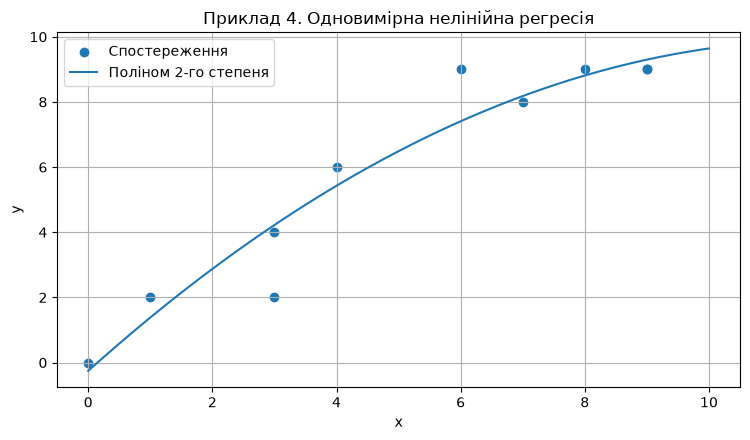

In [14]:
x4 = np.array([8, 0, 3, 4, 9, 7, 1, 6, 3, 9], dtype=float).reshape(-1, 1)
y4 = np.array([9, 0, 2, 6, 9, 8, 2, 9, 4, 9], dtype=float)
poly4 = PolynomialFeatures(degree=2)
X4_poly = poly4.fit_transform(x4)
mod4 = LinearRegression().fit(X4_poly, y4)
print("Поліноміальні ознаки:", poly4.get_feature_names_out(["x"]))
print("Коефіцієнти:", np.round(mod4.coef_, 6), "вільний член:", round(mod4.intercept_, 6))
print("R²:", round(mod4.score(X4_poly, y4), 6))
xx = np.linspace(0, 10, 300).reshape(-1, 1)
plt.figure(figsize=(7.6, 4.5))
plt.scatter(x4[:, 0], y4, label="Спостереження")
plt.plot(xx[:, 0], mod4.predict(poly4.transform(xx)), label="Поліном 2-го степеня")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Приклад 4. Одновимірна нелінійна регресія")
plt.legend(); finish("01_example04_polynomial_1d.png")

## 2. Приклад №5 — двовимірна нелінійна регресія (с. 11–13)

Використовуємо ті самі 9 точок, що в методичці, і квадратичні поліноміальні ознаки двох змінних: `x0`, `x1`, `x0²`, `x0·x1`, `x1²`.

Поліноміальні ознаки: ['1' 'x0' 'x1' 'x0^2' 'x0 x1' 'x1^2']
Коефіцієнти: [ 0.       -1.083333 -1.083333  0.833333  1.25      0.833333] вільний член: 0.694444
R²: 0.910348


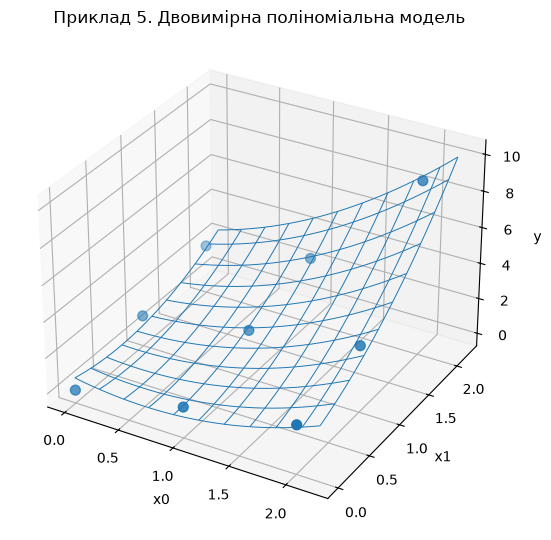

In [15]:
X5 = np.array([[0,1,2,0,1,2,0,1,2], [0,0,0,1,1,1,2,2,2]], dtype=float).T
y5 = np.array([0,1,2,1,2,3,2,3,9], dtype=float)
poly5 = PolynomialFeatures(degree=2)
X5_poly = poly5.fit_transform(X5)
mod5 = LinearRegression().fit(X5_poly, y5)
print("Поліноміальні ознаки:", poly5.get_feature_names_out(["x0", "x1"]))
print("Коефіцієнти:", np.round(mod5.coef_, 6), "вільний член:", round(mod5.intercept_, 6))
print("R²:", round(mod5.score(X5_poly, y5), 6))
g0, g1 = np.meshgrid(np.linspace(0, 2.2, 30), np.linspace(0, 2.2, 30))
grid5 = np.column_stack([g0.ravel(), g1.ravel()])
zz = mod5.predict(poly5.transform(grid5)).reshape(g0.shape)
fig = plt.figure(figsize=(8, 5.5)); ax = fig.add_subplot(111, projection="3d")
ax.scatter(X5[:, 0], X5[:, 1], y5, s=50, label="Дані")
ax.plot_wireframe(g0, g1, zz, rstride=3, cstride=3, linewidth=0.7)
ax.set(xlabel="x0", ylabel="x1", zlabel="y", title="Приклад 5. Двовимірна поліноміальна модель")
finish("02_example05_polynomial_2d.png")

## 3. Приклад №8 — регресійна модель «багатошаровий перцептрон» (с. 16–17)

Порівняємо нейронні мережі з **одним прихованим шаром** із 1 та 2 нейронів (як у методичці). Виведемо ваги та зсуви. Випадкова ініціалізація зроблена відтворюваною.

MLP (1,): R²=0.958346; ваги= [array([[-0.752]]), array([[-4.0024]])]
Зсуви: [array([2.7309]), array([4.8556])]
MLP (2,): R²=0.974910; ваги= [array([[-3.3123, -0.7411]]), array([[-2.8723],
       [-3.4494]])]
Зсуви: [array([13.2192, -0.1146]), array([2.4785])]


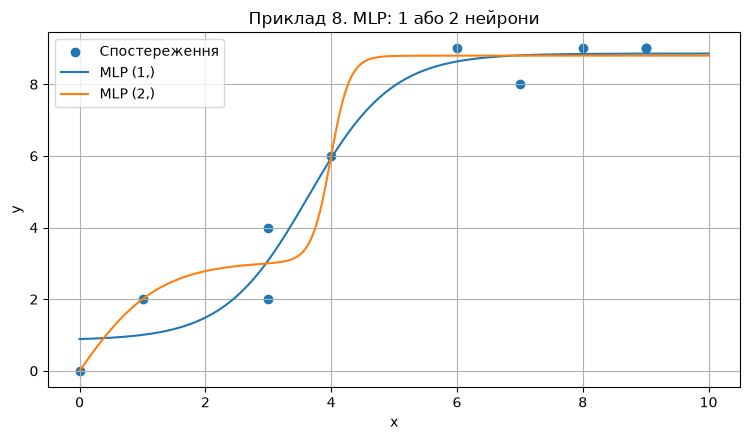

In [16]:
x8 = x4.copy(); y8 = y4.copy()
plt.figure(figsize=(7.6, 4.5)); plt.scatter(x8[:,0], y8, label="Спостереження")
for n in (1, 2):
    model = MLPRegressor(hidden_layer_sizes=(n,), solver="lbfgs", activation="tanh",
                         alpha=0, max_iter=1500, random_state=SEED)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        model.fit(x8, y8)
    print(f"MLP ({n},): R²={model.score(x8,y8):.6f}; ваги=", [np.round(w,4) for w in model.coefs_])
    print("Зсуви:", [np.round(b,4) for b in model.intercepts_])
    plt.plot(xx[:,0], model.predict(xx), label=f"MLP ({n},)")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Приклад 8. MLP: 1 або 2 нейрони")
plt.legend(); finish("03_example08_mlp_1d.png")

## 4. Приклад №9 — двовимірна регресія з MLP (с. 18–19)

Навчаємо багатошаровий перцептрон з 1 та 2 нейронами в одному прихованому шарі. Покажемо ваги, зсуви, якість і прогнозні поверхні.

MLP 2D (1,): R²=0.973043
Ваги: [array([[-0.5455],
       [-0.5455]]), array([[-30370.0903]])]
Зсуви: [array([6.6347]), array([30370.7246])]
MLP 2D (2,): R²=0.990266
Ваги: [array([[  -0.6975,    0.6951],
       [   3.5221, -563.42  ]]), array([[-568.1798],
       [-567.8892]])]
Зсуви: [array([ -3.1455, 563.0449]), array([1.6719])]


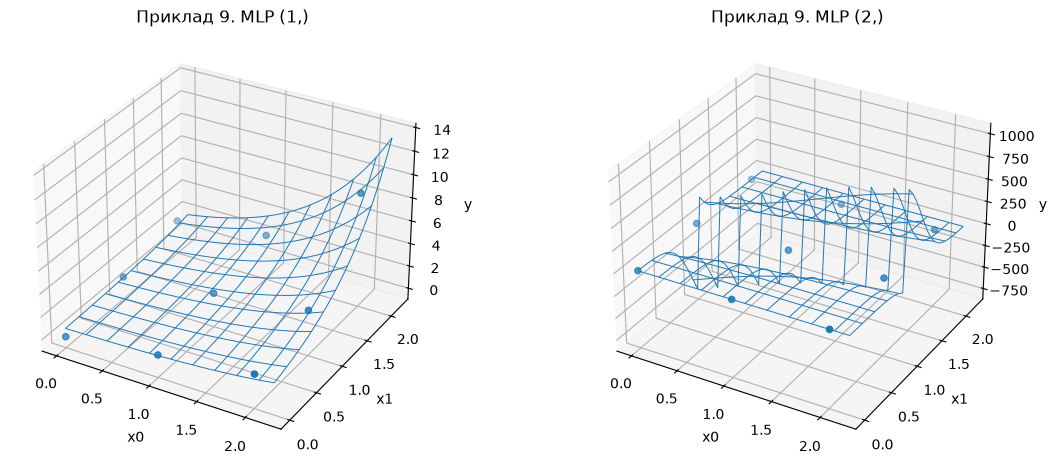

In [17]:
fig = plt.figure(figsize=(12, 4.8))
for i, n in enumerate((1, 2), 1):
    model = MLPRegressor(hidden_layer_sizes=(n,), solver="lbfgs", activation="tanh",
                         alpha=0, max_iter=1500, random_state=SEED)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        model.fit(X5, y5)
    print(f"MLP 2D ({n},): R²={model.score(X5,y5):.6f}")
    print("Ваги:", [np.round(w, 4) for w in model.coefs_])
    print("Зсуви:", [np.round(b, 4) for b in model.intercepts_])
    z = model.predict(grid5).reshape(g0.shape)
    ax = fig.add_subplot(1, 2, i, projection="3d")
    ax.scatter(X5[:,0], X5[:,1], y5)
    ax.plot_wireframe(g0, g1, z, rstride=3, cstride=3, linewidth=0.7)
    ax.set(xlabel="x0", ylabel="x1", zlabel="y", title=f"Приклад 9. MLP ({n},)")
finish("04_example09_mlp_2d.png")

## 5. Приклад №10 — перевірка на тестових даних (с. 19–20)

Відокремлюємо 25% даних **лише для перевірки**. Результати на навчальній та тестовій вибірках порівнюються, щоб оцінити узагальнення моделі.

Коефіцієнт: [1.03682171] вільний член: 0.40310077519380005
R² навчання = 0.933838
R² тест      = 0.614720
R² усіх      = 0.892153


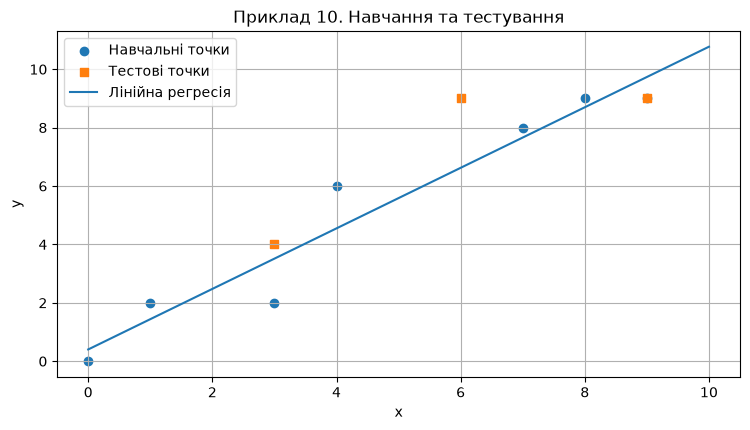

In [18]:
X10tr, X10te, y10tr, y10te = train_test_split(x4, y4, test_size=0.25, random_state=SEED)
mod10 = LinearRegression().fit(X10tr, y10tr)
print("Коефіцієнт:", mod10.coef_, "вільний член:", mod10.intercept_)
print(f"R² навчання = {mod10.score(X10tr, y10tr):.6f}")
print(f"R² тест      = {mod10.score(X10te, y10te):.6f}")
print(f"R² усіх      = {mod10.score(x4, y4):.6f}")
plt.figure(figsize=(7.6, 4.4))
plt.scatter(X10tr[:,0], y10tr, label="Навчальні точки")
plt.scatter(X10te[:,0], y10te, marker="s", label="Тестові точки")
plt.plot(xx[:,0], mod10.predict(xx), label="Лінійна регресія")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Приклад 10. Навчання та тестування")
plt.legend(); finish("05_example10_train_test.png")

## 6. Приклад №11 — перехресна перевірка (с. 20–21)

Застосуємо `KFold` (3 частини) та `ShuffleSplit` (3 випадкові розбиття, 50% тестових даних). Важливо: **оцінка визначається на частині, яку не використовували під час навчання**.

3-fold R²: [0.818628 0.934877 0.61472 ] середнє: 0.789408
ShuffleSplit R²: [0.808043 0.810003 0.831558] середнє: 0.816535
Розбиття 1: train=[9, 3, 0, 6, 5]; test=[8, 4, 7, 2, 1]
Розбиття 2: train=[3, 5, 0, 1, 8]; test=[6, 2, 7, 4, 9]
Розбиття 3: train=[2, 6, 5, 9, 8]; test=[1, 7, 3, 0, 4]


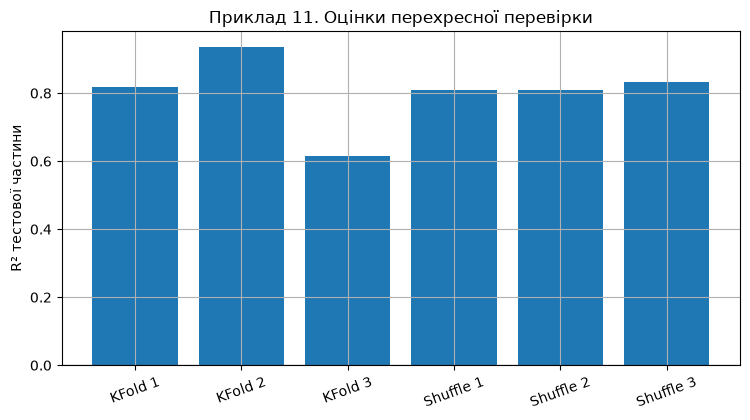

In [19]:
cv11 = KFold(n_splits=3, shuffle=False)
sc11 = cross_val_score(LinearRegression(), x4, y4, cv=cv11, scoring="r2")
cv11_shuffle = ShuffleSplit(n_splits=3, test_size=0.5, random_state=SEED)
sc11_shuffle = cross_val_score(LinearRegression(), x4, y4, cv=cv11_shuffle, scoring="r2")
print("3-fold R²:", np.round(sc11,6), "середнє:", round(sc11.mean(), 6))
print("ShuffleSplit R²:", np.round(sc11_shuffle,6), "середнє:", round(sc11_shuffle.mean(), 6))
for i, (tr, te) in enumerate(cv11_shuffle.split(x4), 1):
    print(f"Розбиття {i}: train={tr.tolist()}; test={te.tolist()}")
plt.figure(figsize=(7.6, 4.3))
labels = [f"KFold {i}" for i in (1,2,3)] + [f"Shuffle {i}" for i in (1,2,3)]
plt.bar(labels, np.r_[sc11,sc11_shuffle]); plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("R² тестової частини"); plt.title("Приклад 11. Оцінки перехресної перевірки")
plt.xticks(rotation=20); finish("06_example11_cross_validation.png")

## 7. Власні задачі №3 і №4: метод вибору моделі

1. Згенеруємо дані **точно за формулами методички** з параметрами варіанта №9.
2. Дослідимо поліноми **1-го, 2-го, 3-го та 4-го степенів**.
3. Дослідимо MLP із **1, 2, 3 прихованими шарами** та різною кількістю нейронів: `(4,)`, `(8,)`, `(4,4)`, `(8,4)`, `(4,4,4)`, `(8,4,2)`.
4. Для чесного порівняння використаємо той самий **5-блоковий KFold** для всіх моделей. Головна метрика — **RMSE валідації** (менша помилка краща). Додатково — `R²` на всіх даних.
5. Для MLP масштабуємо `X` і `y` **всередині конвеєра**, щоб не допустити витоку даних під час CV. Самі початкові дані не змінюємо.

**Уточнення про метрики:** `R²` на тренувальних даних здатний приховати перенавчання. Для задачі №3 шум має стандартне відхилення **1000** за методичкою, тому навіть хороша модель може давати істотну помилку.

In [20]:
ARCHS = [(4,), (8,), (4, 4), (8, 4), (4, 4, 4), (8, 4, 2)]
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)

def make_poly(degree):
    return make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), LinearRegression())

def make_mlp(arch):
    # Змінні X і y масштабуються ТІЛЬКИ на навчальних частинах CV.
    return make_pipeline(
        StandardScaler(),
        TransformedTargetRegressor(
            regressor=MLPRegressor(hidden_layer_sizes=arch, solver="lbfgs", activation="tanh",
                                   alpha=0.1, max_iter=600, random_state=SEED),
            transformer=StandardScaler(),
        ),
    )

def compare_models(X, y, label):
    candidates = [(f"Поліном {deg}", "Поліном", str(deg), make_poly(deg)) for deg in range(1,5)]
    candidates += [(f"MLP {arch}", "MLP", str(arch), make_mlp(arch)) for arch in ARCHS]
    rows = []
    for name, family, option, model in candidates:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            rmses = -cross_val_score(model, X, y, cv=CV, scoring="neg_root_mean_squared_error")
            model.fit(X, y)
        rows.append(dict(Модель=name, Тип=family, Параметри=option,
                         CV_RMSE=float(rmses.mean()), CV_RMSE_std=float(rmses.std()),
                         R2_навчання=float(r2_score(y, model.predict(X))),
                         fitted_model=model))
    result = pd.DataFrame(rows).sort_values("CV_RMSE").reset_index(drop=True)
    printable = result.drop(columns="fitted_model").copy()
    print("\n" + label + ". Порівняння моделей (CV_RMSE — менше краще):")
    print(printable.round(3).to_string(index=False))
    print("Найкраща модель:", result.iloc[0]["Модель"], "; CV_RMSE =", round(result.iloc[0]["CV_RMSE"],3))
    printable.to_csv(OUT / f"{label}_models.csv", index=False, encoding="utf-8-sig")
    return result

def print_model_parameters(row, X, y):
    m = row["fitted_model"]
    print("Коефіцієнти / параметри обраної моделі:")
    if row["Тип"] == "Поліном":
        pol, lin = m.steps[0][1], m.steps[1][1]
        print("Назви ознак:", pol.get_feature_names_out([f"x{i}" for i in range(X.shape[1])]))
        print("Коефіцієнти:", np.round(lin.coef_, 5))
        print("Вільний член:", round(float(lin.intercept_), 5))
    else:
        mlp = m.steps[1][1].regressor_
        for i, (w, b) in enumerate(zip(mlp.coefs_, mlp.intercepts_), 1):
            print(f"Шар {i}: ваги ({w.shape[0]} × {w.shape[1]}) = ", np.round(w, 4))
            print(f"Шар {i}: зсуви = ", np.round(b, 4))
        print("Примітка: ці ваги стосуються масштабованих ознак і цільової змінної.")
    print(f"R² на всіх точках = {r2_score(y, m.predict(X)):.6f}")

def show_cv_bar(results, outfile, heading):
    plt.figure(figsize=(10.5, 5))
    view = results.sort_values("CV_RMSE", ascending=False)
    plt.barh(view["Модель"], view["CV_RMSE"], xerr=view["CV_RMSE_std"], capsize=2)
    plt.xlabel("RMSE перехресної перевірки (менше — краще)")
    plt.title(heading)
    finish(outfile)

## 8. Задача №3 — одновимірна поліноміальна регресія (с. 55)

За методичкою:

\[
 x=0,1,\dots,19;\qquad y=ax^3+bx^2+cx+d+\varepsilon,\quad\varepsilon\sim\mathcal N(0,1000^2).
\]

Для варіанта №9:

\[
 \boxed{y=x^3+2x^2+3+\varepsilon.}
\]

Знайдемо найкращу модель через перехресну перевірку; покажемо коефіцієнти, `R²`, прогноз у точці `x=10.5` та графіки.

In [ ]:
rng3 = np.random.default_rng(SEED)
x3 = np.arange(0,20, dtype=float).reshape(-1,1)
y3 = A*x3[:,0]**3 + B*x3[:,0]**2 + C*x3[:,0] + D + rng3.normal(0, 10**3, 20)
print("Задача 3: 20 точок, шум sigma=1000, варіант №9")
res3 = compare_models(x3, y3, "task03")
print_model_parameters(res3.iloc[0], x3, y3)
print("Прогноз найкращої моделі в x=10.5:", float(res3.iloc[0]["fitted_model"].predict([[10.5]])[0]))
print("CV-RMSE найкращої моделі:", round(res3.iloc[0]["CV_RMSE"], 6))
show_cv_bar(res3, "07_task03_cv_rmse.png", "Задача 3. Порівняння поліномів і MLP")

Задача 3: 20 точок, шум sigma=1000, варіант №9


In [ ]:
plt.figure(figsize=(9.2, 5.1))
plt.scatter(x3[:,0], y3, label="Згенеровані дані", zorder=5)
xx3 = np.linspace(0,19,300).reshape(-1,1)
plt.plot(xx3[:,0], A*xx3[:,0]**3+B*xx3[:,0]**2+C*xx3[:,0]+D, "--", label="Дійсна залежність без шуму")
for deg in range(1,5):
    model = res3.loc[res3["Модель"]==f"Поліном {deg}","fitted_model"].iloc[0]
    plt.plot(xx3[:,0], model.predict(xx3), alpha=0.75, label=f"Поліном {deg}")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Задача 3. Дані та поліноміальні моделі")
plt.legend(ncol=2); finish("08_task03_polynomials.png")

plt.figure(figsize=(9.2, 5.1)); plt.scatter(x3[:,0], y3, label="Дані", zorder=5)
for family, style in (("Поліном", "--"), ("MLP", "-")):
    row = res3.loc[res3["Тип"]==family].iloc[0]
    plt.plot(xx3[:,0], row["fitted_model"].predict(xx3), style, linewidth=2,
             label=f"Кращий {family}: {row['Модель']}")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Задача 3. Найкращий поліном і MLP")
plt.legend(); finish("09_task03_best_models.png")

## 9. Задача №4 — двовимірна поліноміальна регресія (с. 56)

Для сітки `x0, x1 ∈ {0,1,2,3,4}` (25 точок) генерація за методичкою:

\[
 y=ax_0^2+bx_1^2+cx_0x_1+dx_0+ax_1+b+\varepsilon,\quad
 \varepsilon\sim\mathcal N(0,(1+d)^2).
\]

Для варіанта №9 (`a=1,b=2,c=0,d=3`):

\[
 \boxed{y=x_0^2+2x_1^2+3x_0+x_1+2+\varepsilon,\quad\sigma=4.}
\]

Порівнюємо всі 10 моделей, обираємо найкращу за RMSE CV, виводимо коефіцієнти та `R²`, прогноз у точці `(2.5, 3.5)` і прогнозні поверхні.

In [ ]:
coords = np.array([[0,1,2,3,4]*5,
                   [0]*5+[1]*5+[2]*5+[3]*5+[4]*5], dtype=float)
x2 = coords.T
rng4 = np.random.default_rng(SEED)
y2 = (A*x2[:,0]**2 + B*x2[:,1]**2 + C*x2[:,0]*x2[:,1]
      + D*x2[:,0] + A*x2[:,1] + B + rng4.normal(0,1+D,25))
print("Задача 4: 25 точок, шум sigma=4, варіант №9")
res4 = compare_models(x2, y2, "task04")
print_model_parameters(res4.iloc[0], x2, y2)
print("Прогноз найкращої моделі в (2.5, 3.5):", float(res4.iloc[0]["fitted_model"].predict([[2.5,3.5]])[0]))
print("CV-RMSE найкращої моделі:", round(res4.iloc[0]["CV_RMSE"], 6))
show_cv_bar(res4, "10_task04_cv_rmse.png", "Задача 4. Порівняння поліномів і MLP")

In [ ]:
g0, g1 = np.meshgrid(np.linspace(0,4,35), np.linspace(0,4,35))
Xgrid = np.column_stack([g0.ravel(),g1.ravel()])
fig = plt.figure(figsize=(13, 5))
for i, family in enumerate(("Поліном", "MLP"), 1):
    row = res4.loc[res4["Тип"]==family].iloc[0]
    zg = row["fitted_model"].predict(Xgrid).reshape(g0.shape)
    ax = fig.add_subplot(1,2,i,projection="3d")
    ax.scatter(x2[:,0], x2[:,1], y2, s=28)
    ax.plot_wireframe(g0, g1, zg, rstride=3, cstride=3, linewidth=0.7)
    ax.set(xlabel="x0",ylabel="x1",zlabel="y",title=f"Задача 4: {row['Модель']}")
finish("11_task04_best_surfaces.png")

row = res4.iloc[0]
zg = row["fitted_model"].predict(Xgrid).reshape(g0.shape)
fig = plt.figure(figsize=(7.9,5.6)); ax = fig.add_subplot(111, projection="3d")
ax.scatter(x2[:,0],x2[:,1],y2,s=45,label="Згенеровані точки")
ax.plot_surface(g0,g1,zg,alpha=0.52)
ax.set(xlabel="x0",ylabel="x1",zlabel="y",title=f"Задача 4. Найкраща модель: {row['Модель']}")
finish("12_task04_selected_surface.png")

## 10. ВИСНОВОК

У лабораторній роботі досліджено нелінійну регресію, побудову поліноміальних ознак, багатошарові перцептрони, перевірку моделей на тестових даних і перехресну перевірку. Опрацьовано приклади №4, №5, №8–11 з методичних вказівок.

Для задач №3 і №4 варіанта 9 порівняно поліноміальні моделі 1–4 степенів і нейронні мережі MLP з одним, двома та трьома прихованими шарами. За результатами перехресної перевірки найкращою для задачі №3 виявилася модель полінома 3-го степеня (CV-RMSE ≈ 1338,434), а для задачі №4 — поліном 2-го степеня (CV-RMSE ≈ 4,634).

Отримані результати показують важливість оцінювання моделей на даних, не використаних для їх навчання. Ускладнення архітектури нейронної мережі або збільшення степеня полінома не гарантує зменшення помилки прогнозування.
